**HW2
Chelsea Ankenbrandt**

**Question 1**

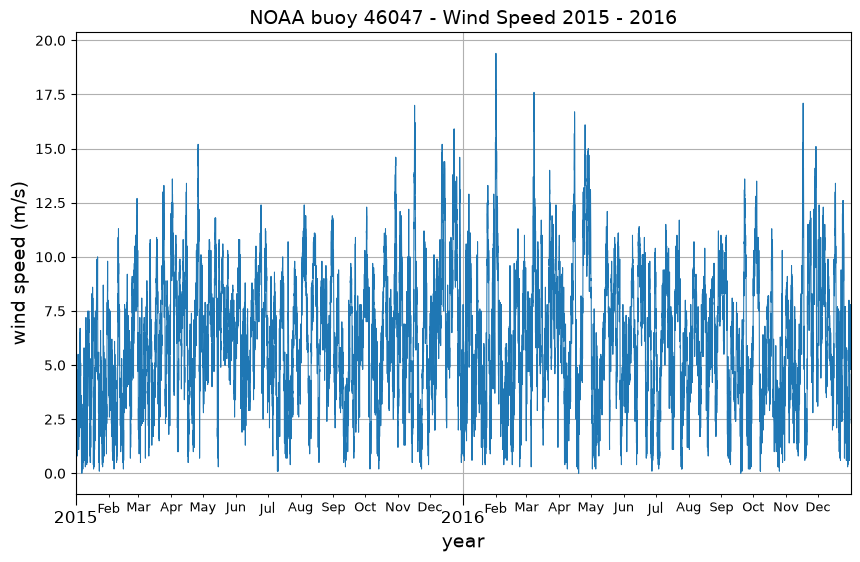

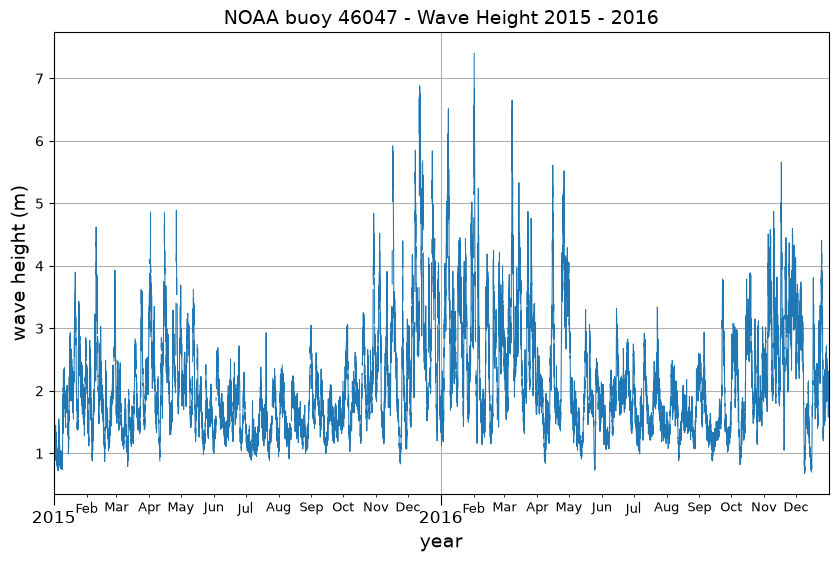

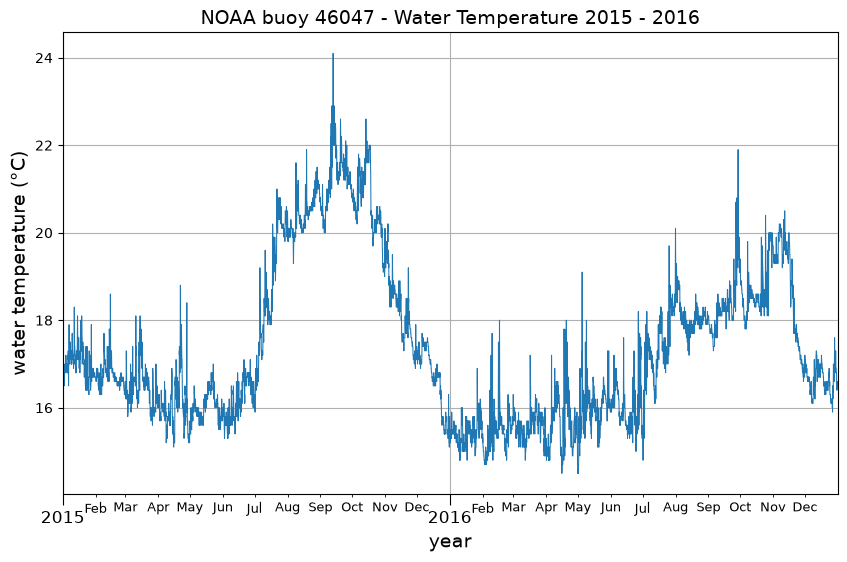

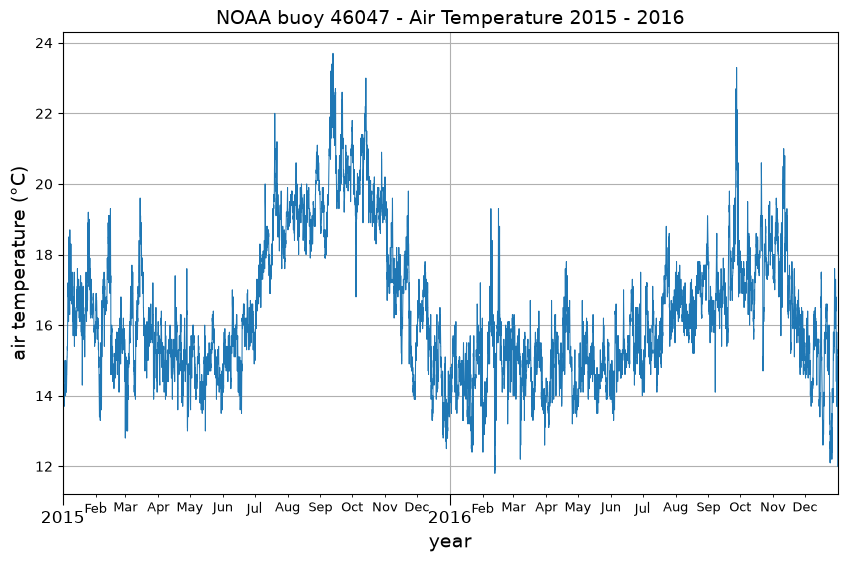

In [2]:
import os
from dataclasses import dataclass, field

import datetime
import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import pandas as pd
from scipy.stats import chi2


#Question 1

#read in 2015 data
buoy_data2015 = pd.read_csv(r"C:\Users\cva43\SIO221a_Ankenbrandt\data\46047_2015.txt", 
                        sep=r"\s+", 
                        skiprows=[1], 
                        parse_dates=True, 
                        na_values=["99.0", "999", "999.0", "9999.0", "99.00"],)

#read in 2016 data
buoy_data2016 = pd.read_csv(r"C:\Users\cva43\SIO221a_Ankenbrandt\data\46047_2016.txt", 
                        sep=r"\s+", 
                        skiprows=[1], 
                        parse_dates=True, 
                        na_values=["99.0", "999", "999.0", "9999.0", "99.00"],)

#combine years into a single df
buoy_data = pd.concat([buoy_data2015, buoy_data2016], ignore_index=True)

#convert date columns to datetime format
buoy_data['date'] = pd.to_datetime({'year': buoy_data['#YY'], 
                                    'month': buoy_data['MM'], 
                                    'day': buoy_data['DD'], 
                                    'hour': buoy_data['hh'], 
                                    'minute': buoy_data['mm']})

#remove original date columns + set datetime as index
buoy_data.drop(columns=['#YY', 'MM', 'DD', 'hh', 'mm'], inplace=True)
buoy_data.set_index('date', inplace=True)


#plot wind speed data for 2015-2016
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(buoy_data.index, buoy_data['WSPD'], linewidth=.75)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax.tick_params(axis='x', which='major', labelsize=12, length=8)
ax.tick_params(axis='x', which='minor', labelsize=9) 
ax.set_xlim(buoy_data.index.min(), buoy_data.index.max())
ax.set_xlabel('year', fontsize=14)
ax.set_ylabel('wind speed (m/s)', fontsize=14)
ax.set_title('NOAA buoy 46047 - Wind Speed 2015 - 2016', fontsize=14)
ax.grid(True)

#plot wave height for 2015-2016
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(buoy_data.index, buoy_data['WVHT'], linewidth=.75)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.xaxis.set_minor_locator(mdates.MonthLocator())
ax1.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax1.tick_params(axis='x', which='major', labelsize=12, length=8)
ax1.tick_params(axis='x', which='minor', labelsize=9) 
ax1.set_xlim(buoy_data.index.min(), buoy_data.index.max())
ax1.set_xlabel('year', fontsize=14)
ax1.set_ylabel('wave height (m)', fontsize=14)
ax1.set_title('NOAA buoy 46047 - Wave Height 2015 - 2016', fontsize=14)
ax1.grid(True)

#plot water temperature for 2015-2016
fig, ax2 = plt.subplots(figsize=(10, 6))
ax2.plot(buoy_data.index, buoy_data['WTMP'], linewidth=.75)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.xaxis.set_minor_locator(mdates.MonthLocator())
ax2.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax2.tick_params(axis='x', which='major', labelsize=12, length=8)
ax2.tick_params(axis='x', which='minor', labelsize=9) 
ax2.set_xlim(buoy_data.index.min(), buoy_data.index.max())
ax2.set_xlabel('year', fontsize=14)
ax2.set_ylabel('water temperature (°C)', fontsize=14)
ax2.set_title('NOAA buoy 46047 - Water Temperature 2015 - 2016', fontsize=14)
ax2.grid(True)

#plot air temperature for 2015-2016
fig, ax3 = plt.subplots(figsize=(10, 6))
ax3.plot(buoy_data.index, buoy_data['ATMP'], linewidth=.75)
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax3.xaxis.set_minor_locator(mdates.MonthLocator())
ax3.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax3.tick_params(axis='x', which='major', labelsize=12, length=8)
ax3.tick_params(axis='x', which='minor', labelsize=9) 
ax3.set_xlim(buoy_data.index.min(), buoy_data.index.max())
ax3.set_xlabel('year', fontsize=14)
ax3.set_ylabel('air temperature (°C)', fontsize=14)
ax3.set_title('NOAA buoy 46047 - Air Temperature 2015 - 2016', fontsize=14)
ax3.grid(True)
plt.show()

Missing data are identified using 99.0, 999.0, 99.00, and various permutations thereof! I included in my code a translation from these values to NaN values so that I don't plot them by accident.

**Question 2**

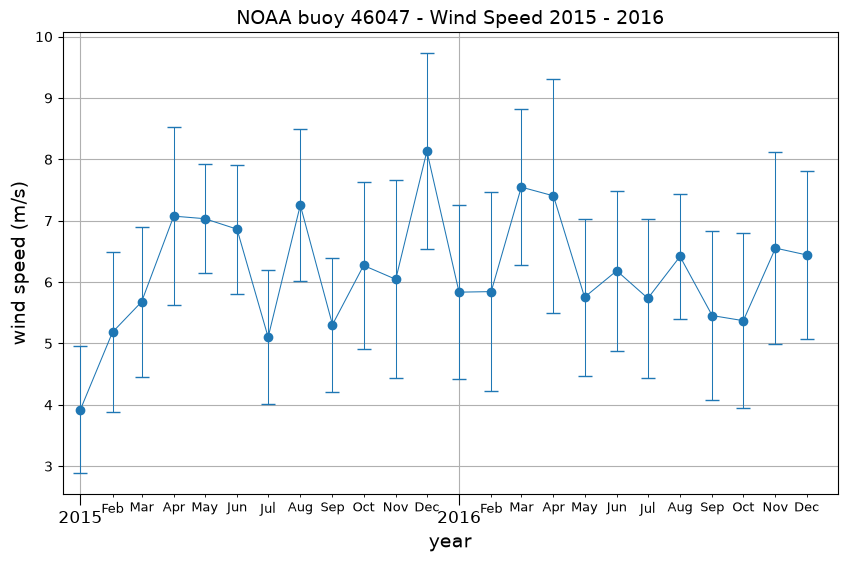

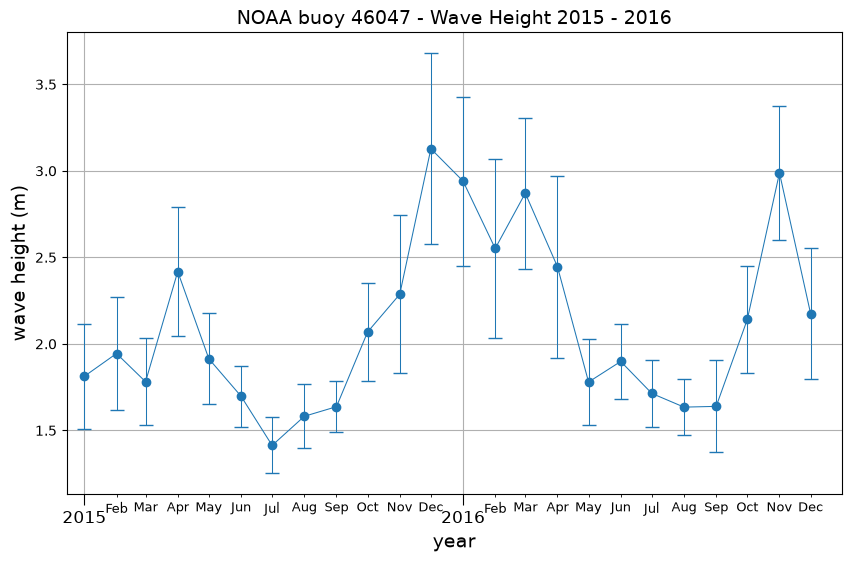

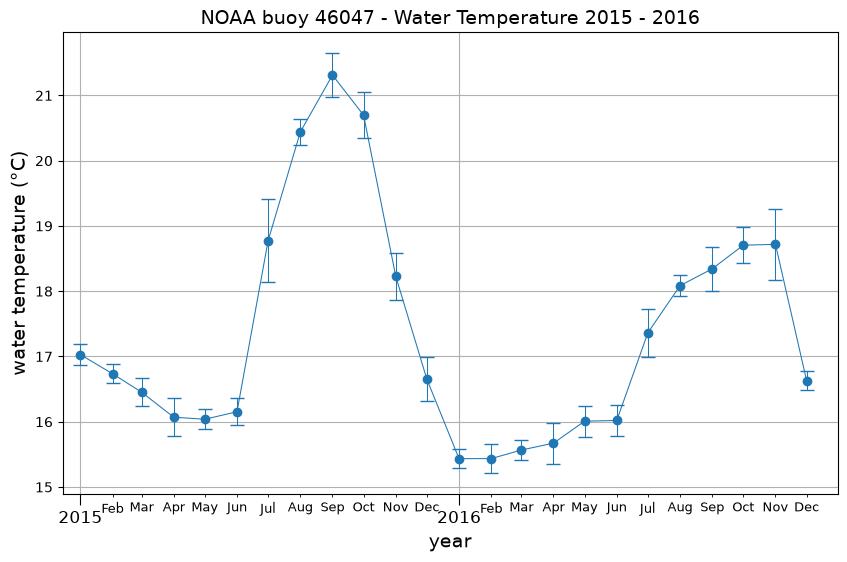

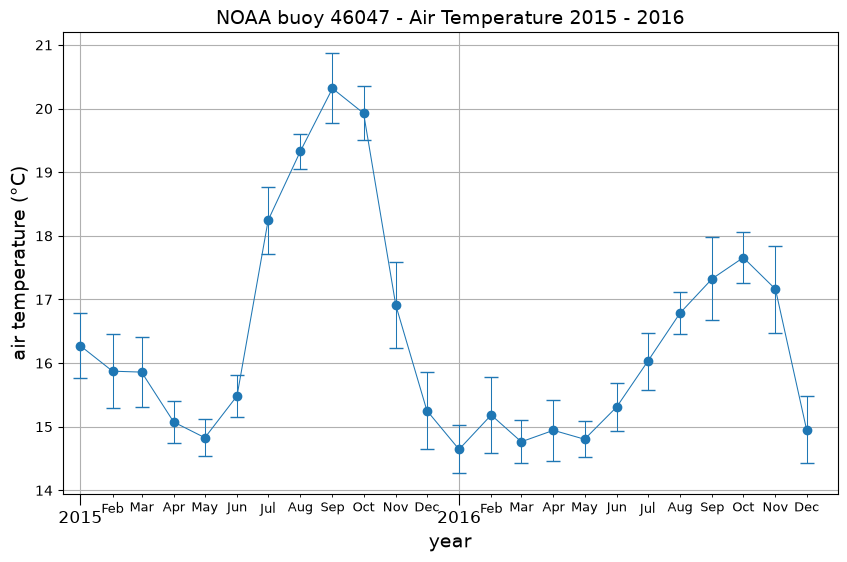

In [3]:
# cutting off 2014 and 2017 data for prettier plots
buoy_data = buoy_data.iloc[1:-1]

# getting monthly means of everything at MonthStart (MS) for plotting
monthly_mean_buoy_data = buoy_data.resample('MS').mean()
monthly_std_buoy_data = buoy_data.resample('MS').std()
n_eff = pd.Series(monthly_mean_buoy_data.index.days_in_month / 7, index=monthly_mean_buoy_data.index) # type: ignore
#lmao I just spent 10 minutes chasing the error of why feb16 doesnt have 28 dyas

#get that standard error of the mean babbyyyyyy
monthly_sem_buoy_data = monthly_std_buoy_data.div(np.sqrt(n_eff), axis=0)

#I ended up having to ask Claude for help with data structures in python for the chunk right above
#as I accidentally ended up with half data frames and half arrays of some kind

#plot wind speed data monthly averages w errorbars for 2015-2016
fig, ax4 = plt.subplots(figsize=(10, 6))
#python equivalent of matlab errorbar function
ax4.errorbar(monthly_mean_buoy_data.index, 
             monthly_mean_buoy_data['WSPD'], 
             yerr=monthly_sem_buoy_data['WSPD'], 
             fmt='-o', 
             linewidth=.75, 
             capsize=5)
ax4.xaxis.set_major_locator(mdates.YearLocator())
ax4.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax4.xaxis.set_minor_locator(mdates.MonthLocator())
ax4.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax4.tick_params(axis='x', which='major', labelsize=12, length=8)
ax4.tick_params(axis='x', which='minor', labelsize=9) 
ax4.set_xlim(pd.Timestamp('2014-12-15'), pd.Timestamp('2016-12-31')) # type: ignore
ax4.set_xlabel('year', fontsize=14)
ax4.set_ylabel('wind speed (m/s)', fontsize=14)
ax4.set_title('NOAA buoy 46047 - Wind Speed 2015 - 2016', fontsize=14)
ax4.grid(True)


#plot wave height data monthly averages w errorbars for 2015-2016
fig, ax5 = plt.subplots(figsize=(10, 6))
#python equivalent of matlab errorbar function
ax5.errorbar(monthly_mean_buoy_data.index, 
             monthly_mean_buoy_data['WVHT'], 
             yerr=monthly_sem_buoy_data['WVHT'], 
             fmt='-o', 
             linewidth=.75, 
             capsize=5)
ax5.xaxis.set_major_locator(mdates.YearLocator())
ax5.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax5.xaxis.set_minor_locator(mdates.MonthLocator())
ax5.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax5.tick_params(axis='x', which='major', labelsize=12, length=8)
ax5.tick_params(axis='x', which='minor', labelsize=9) 
ax5.set_xlim(pd.Timestamp('2014-12-15'), pd.Timestamp('2016-12-31')) # type: ignore
ax5.set_xlabel('year', fontsize=14)
ax5.set_ylabel('wave height (m)', fontsize=14)
ax5.set_title('NOAA buoy 46047 - Wave Height 2015 - 2016', fontsize=14)
ax5.grid(True)


#plot water temperature data monthly averages w errorbars for 2015-2016
fig, ax6 = plt.subplots(figsize=(10, 6))
#python equivalent of matlab errorbar function
ax6.errorbar(monthly_mean_buoy_data.index, 
             monthly_mean_buoy_data['WTMP'], 
             yerr=monthly_sem_buoy_data['WTMP'], 
             fmt='-o', 
             linewidth=.75, 
             capsize=5)
ax6.xaxis.set_major_locator(mdates.YearLocator())
ax6.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax6.xaxis.set_minor_locator(mdates.MonthLocator())
ax6.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax6.tick_params(axis='x', which='major', labelsize=12, length=8)
ax6.tick_params(axis='x', which='minor', labelsize=9) 
ax6.set_xlim(pd.Timestamp('2014-12-15'), pd.Timestamp('2016-12-31')) # type: ignore
ax6.set_xlabel('year', fontsize=14)
ax6.set_ylabel('water temperature (°C)', fontsize=14)
ax6.set_title('NOAA buoy 46047 - Water Temperature 2015 - 2016', fontsize=14)
ax6.grid(True)

#plot air temperature data monthly averages w errorbars for 2015-2016
fig, ax7 = plt.subplots(figsize=(10, 6))
#python equivalent of matlab errorbar function
ax7.errorbar(monthly_mean_buoy_data.index, 
             monthly_mean_buoy_data['ATMP'], 
             yerr=monthly_sem_buoy_data['ATMP'], 
             fmt='-o', 
             linewidth=.75, 
             capsize=5)
ax7.xaxis.set_major_locator(mdates.YearLocator())
ax7.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax7.xaxis.set_minor_locator(mdates.MonthLocator())
ax7.xaxis.set_minor_formatter(mdates.DateFormatter('%b'))
ax7.tick_params(axis='x', which='major', labelsize=12, length=8)
ax7.tick_params(axis='x', which='minor', labelsize=9) 
ax7.set_xlim(pd.Timestamp('2014-12-15'), pd.Timestamp('2016-12-31')) # type: ignore
ax7.set_xlabel('year', fontsize=14)
ax7.set_ylabel('air temperature (°C)', fontsize=14)
ax7.set_title('NOAA buoy 46047 - Air Temperature 2015 - 2016', fontsize=14)
ax7.grid(True)
plt.show()

**Question 3**

In [4]:
#Clean up 2015 and 2016 data
#convert date columns to datetime format
buoy_data2015['date'] = pd.to_datetime({'year': buoy_data2015['#YY'], 
                                    'month': buoy_data2015['MM'], 
                                    'day': buoy_data2015['DD'], 
                                    'hour': buoy_data2015['hh'], 
                                    'minute': buoy_data2015['mm']})

#remove original date columns + set datetime as index
buoy_data2015.drop(columns=['#YY', 'MM', 'DD', 'hh', 'mm'], inplace=True)
buoy_data2015.set_index('date', inplace=True)

buoy_data2016['date'] = pd.to_datetime({'year': buoy_data2016['#YY'], 
                                    'month': buoy_data2016['MM'], 
                                    'day': buoy_data2016['DD'], 
                                    'hour': buoy_data2016['hh'], 
                                    'minute': buoy_data2016['mm']})

#remove original date columns + set datetime as index
buoy_data2016.drop(columns=['#YY', 'MM', 'DD', 'hh', 'mm'], inplace=True)
buoy_data2016.set_index('date', inplace=True)


# getting monthly means of everything at MonthStart (MS) for plotting
monthly_mean_buoy_data2015 = buoy_data2015.resample('MS').mean()
monthly_mean_buoy_data2016 = buoy_data2016.resample('MS').mean()

#chopping off stray months
monthly_mean_buoy_data2015 = monthly_mean_buoy_data2015.iloc[1:13]
monthly_mean_buoy_data2016 = monthly_mean_buoy_data2016.iloc[1:13]

#now to the most complicated way to get an array of[0:12]
time = monthly_mean_buoy_data2015.index.month - monthly_mean_buoy_data2015.index[0].month # type: ignore


#let's try to get some leastsquares from 2015
A = np.column_stack([np.ones_like(time, dtype=float), # type: ignore
                         time, # type: ignore
                         np.sin(2*np.pi*time/12), # type: ignore
                         np.cos(2*np.pi*time/12)])  # type: ignore


#2015 WTMP
x_2015_WTMP, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2015['WTMP'], rcond=None)
print("The mean water temp for 2015 is: %.4g" % x_2015_WTMP[0], 
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_WTMP[2]**2 + x_2015_WTMP[3]**2))


#2016 WTMP
x_2016_WTMP, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2016['WTMP'], rcond=None)
print("The mean water temp for 2016 is: %.4g" % x_2016_WTMP[0], 
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_WTMP[2]**2 + x_2016_WTMP[3]**2))

#2015 ATMP
x_2015_ATMP, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2015['ATMP'], rcond=None)
print("The mean air temp for 2015 is: %.4g" % x_2015_ATMP[0],
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_ATMP[2]**2 + x_2015_ATMP[3]**2))

#2016 ATMP
x_2016_ATMP, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2016['ATMP'], rcond=None)
print("The mean air temp for 2016 is: %.4g" % x_2016_ATMP[0],
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_ATMP[2]**2 + x_2016_ATMP[3]**2))

#2015 WSPD
x_2015_WSPD, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2015['WSPD'], rcond=None)
print("The mean wind speed for 2015 is: %.4g" % x_2015_WSPD[0], 
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_WSPD[2]**2 + x_2015_WSPD[3]**2))

#2016 WSPD
x_2016_WSPD, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2016['WSPD'], rcond=None)
print("The mean wind speed for 2016 is: %.4g" % x_2016_WSPD[0], 
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_WSPD[2]**2 + x_2016_WSPD[3]**2))

#2015 WVHT
x_2015_WVHT, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2015['WVHT'], rcond=None)
print("The mean wave height for 2015 is: %.4g" % x_2015_WVHT[0], 
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_WVHT[2]**2 + x_2015_WVHT[3]**2))

#2016 WVHT
x_2016_WVHT, *_ = np.linalg.lstsq(A, monthly_mean_buoy_data2016['WVHT'], rcond=None)
print("The mean wave height for 2016 is: %.4g" % x_2016_WVHT[0], 
      "and the total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_WVHT[2]**2 + x_2016_WVHT[3]**2))



The mean water temp for 2015 is: 19.24 and the total amplitude of the annual cycle is 3.298
The mean water temp for 2016 is: 16.43 and the total amplitude of the annual cycle is 1.405
The mean air temp for 2015 is: 18.7 and the total amplitude of the annual cycle is 3.497
The mean air temp for 2016 is: 15.96 and the total amplitude of the annual cycle is 1.484
The mean wind speed for 2015 is: 3.772 and the total amplitude of the annual cycle is 1.67
The mean wind speed for 2016 is: 5.563 and the total amplitude of the annual cycle is 0.956
The mean wave height for 2015 is: 1.152 and the total amplitude of the annual cycle is 0.7155
The mean wave height for 2016 is: 2.359 and the total amplitude of the annual cycle is 0.5573


For water and air temp, the amplitudes (and means) are significantly different between the two years. I know 2015 was a major el nino, and you can visually see the difference between the years temperature wise on the graphs above. 

For wind speed and wave height, there are differences as well, but not as large as for water and air temperature. I'm interested by the change in amplitude for wind speed - the two years visually look very similar, but there is a significant change is the total amplitude.

**Question 4**

In [5]:
#I think adding a semiannual cycle, we're going to be dividing by 6 in the sine and cosine terms....
A1 = np.column_stack([np.ones_like(time, dtype=float), # type: ignore
                         time, # type: ignore
                         np.sin(2*np.pi*time/12), # type: ignore
                         np.cos(2*np.pi*time/12), # type: ignore
                         np.sin(2*np.pi*time/6), # type: ignore
                         np.cos(2*np.pi*time/6)])  # type: ignore


#2015 WTMP
x_2015_WTMP_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2015['WTMP'], rcond=None)
print("The total semiannual amplitude for the water temp for 2015 is: %.4g" % np.sqrt(x_2015_WTMP_semi[4]**2 + x_2015_WTMP_semi[5]**2), 
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_WTMP_semi[2]**2 + x_2015_WTMP_semi[3]**2))


#2016 WTMP
x_2016_WTMP_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2016['WTMP'], rcond=None)
print("The total semiannual amplitude for the water temp for 2016 is: %.4g" % np.sqrt(x_2016_WTMP_semi[4]**2 + x_2016_WTMP_semi[5]**2), 
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_WTMP_semi[2]**2 + x_2016_WTMP_semi [3]**2))

#2015 ATMP
x_2015_ATMP_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2015['ATMP'], rcond=None)
print("The total semiannual amplitude for the air temp for 2015 is: %.4g" % np.sqrt(x_2015_ATMP_semi[4]**2 + x_2015_ATMP_semi[5]**2),
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_ATMP_semi[2]**2 + x_2015_ATMP_semi[3]**2))

#2016 ATMP
x_2016_ATMP_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2016['ATMP'], rcond=None)
print("The total semiannual amplitude for the air temp for 2016 is: %.4g" % np.sqrt(x_2016_ATMP_semi[4]**2 + x_2016_ATMP_semi[5]**2),
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_ATMP_semi[2]**2 + x_2016_ATMP_semi[3]**2))

#2015 WSPD
x_2015_WSPD_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2015['WSPD'], rcond=None)
print("The total semiannual amplitude for the wind speed for 2015 is: %.4g" % np.sqrt(x_2015_WSPD_semi[4]**2 + x_2015_WSPD_semi[5]**2), 
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_WSPD_semi[2]**2 + x_2015_WSPD_semi[3]**2))

#2016 WSPD
x_2016_WSPD_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2016['WSPD'], rcond=None)
print("The total semiannual amplitude for the wind speed for 2016 is: %.4g" % np.sqrt(x_2016_WSPD_semi[4]**2 + x_2016_WSPD_semi[5]**2), 
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_WSPD_semi[2]**2 + x_2016_WSPD_semi[3]**2))

#2015 WVHT
x_2015_WVHT_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2015['WVHT'], rcond=None)
print("The total semiannual amplitude for the wave height for 2015 is: %.4g" % np.sqrt(x_2015_WVHT_semi[4]**2 + x_2015_WVHT_semi[5]**2), 
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2015_WVHT_semi[2]**2 + x_2015_WVHT_semi[3]**2))

#2016 WVHT
x_2016_WVHT_semi, *_ = np.linalg.lstsq(A1, monthly_mean_buoy_data2016['WVHT'], rcond=None)
print("The total semiannual amplitude for the wave height for 2016 is: %.4g" % np.sqrt(x_2016_WVHT_semi[4]**2 + x_2016_WVHT_semi[5]**2),
      "and the new total amplitude of the annual cycle is %.4g" % np.sqrt(x_2016_WVHT_semi[2]**2 + x_2016_WVHT_semi[3]**2))


The total semiannual amplitude for the water temp for 2015 is: 1.036 and the new total amplitude of the annual cycle is 2.795
The total semiannual amplitude for the water temp for 2016 is: 0.4349 and the new total amplitude of the annual cycle is 1.53
The total semiannual amplitude for the air temp for 2015 is: 1.065 and the new total amplitude of the annual cycle is 2.951
The total semiannual amplitude for the air temp for 2016 is: 0.5548 and the new total amplitude of the annual cycle is 1.585
The total semiannual amplitude for the wind speed for 2015 is: 0.1259 and the new total amplitude of the annual cycle is 1.77
The total semiannual amplitude for the wind speed for 2016 is: 0.3679 and the new total amplitude of the annual cycle is 1.206
The total semiannual amplitude for the wave height for 2015 is: 0.06919 and the new total amplitude of the annual cycle is 0.6675
The total semiannual amplitude for the wave height for 2016 is: 0.1917 and the new total amplitude of the annual cyc

Yes, the amplitude of the annual cycle changes when the semiannual cycle is added!

**Question 4**

In [6]:
#okay I needed more values for 2015 and 2016
monthly_std_buoy_data2015 = buoy_data2015.resample('MS').std()
monthly_std_buoy_data2016 = buoy_data2016.resample('MS').std()

n_eff2015 = n_eff[0:12]
n_eff2016 = n_eff[12:24]

monthly_sem_buoy_data2015 = monthly_std_buoy_data2015.iloc[1:13].div(np.sqrt(n_eff2015), axis=0)
monthly_sem_buoy_data2016 = monthly_std_buoy_data2016.iloc[1:13].div(np.sqrt(n_eff2016), axis=0)

#getting the misfits
#2015 WTMP
misfit_annual_2015_WTMP = ((monthly_mean_buoy_data2015['WTMP'] - (A @ x_2015_WTMP))**2) / ((monthly_sem_buoy_data2015['WTMP'])**2)
misfit_semiannual_2015_WTMP = ((monthly_mean_buoy_data2015['WTMP'] - (A1 @ x_2015_WTMP_semi))**2) / ((monthly_sem_buoy_data2015['WTMP'])**2)
misfit_diff_2015_WTMP = misfit_annual_2015_WTMP.sum() - misfit_semiannual_2015_WTMP.sum()

print("Total misfit for 2015 WTMP (annual only): %.4g" % misfit_annual_2015_WTMP.sum())
print("Total misfit for 2015 WTMP (semiannual included): %.4g" % misfit_semiannual_2015_WTMP.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_WTMP)

#2016 WTMP
misfit_annual_2016_WTMP = ((monthly_mean_buoy_data2016['WTMP'] - (A @ x_2016_WTMP))**2) / ((monthly_sem_buoy_data2016['WTMP'])**2)
misfit_semiannual_2016_WTMP = ((monthly_mean_buoy_data2016['WTMP'] - (A1 @ x_2016_WTMP_semi))**2) / ((monthly_sem_buoy_data2016['WTMP'])**2)
misfit_diff_2016_WTMP = misfit_annual_2016_WTMP.sum() - misfit_semiannual_2016_WTMP.sum()
    
print("Total misfit for 2016 WTMP (annual only): %.4g" % misfit_annual_2016_WTMP.sum())
print("Total misfit for 2016 WTMP (semiannual included): %.4g" % misfit_semiannual_2016_WTMP.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_WTMP)

#2015 ATMP
misfit_annual_2015_ATMP = ((monthly_mean_buoy_data2015['ATMP'] - (A @ x_2015_ATMP))**2) / ((monthly_sem_buoy_data2015['ATMP'])**2)
misfit_semiannual_2015_ATMP = ((monthly_mean_buoy_data2015['ATMP'] - (A1 @ x_2015_ATMP_semi))**2) / ((monthly_sem_buoy_data2015['ATMP'])**2)
misfit_diff_2015_ATMP = misfit_annual_2015_ATMP.sum() - misfit_semiannual_2015_ATMP.sum()

print("Total misfit for 2015 ATMP (annual only): %.4g" % misfit_annual_2015_ATMP.sum())
print("Total misfit for 2015 ATMP (semiannual included): %.4g" % misfit_semiannual_2015_ATMP.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_ATMP)

#2016 ATMP
misfit_annual_2016_ATMP = ((monthly_mean_buoy_data2016['ATMP'] - (A @ x_2016_ATMP))**2) / ((monthly_sem_buoy_data2016['ATMP'])**2)
misfit_semiannual_2016_ATMP = ((monthly_mean_buoy_data2016['ATMP'] - (A1 @ x_2016_ATMP_semi))**2) / ((monthly_sem_buoy_data2016['ATMP'])**2)
misfit_diff_2016_ATMP = misfit_annual_2016_ATMP.sum() - misfit_semiannual_2016_ATMP.sum()

print("Total misfit for 2016 ATMP (annual only): %.4g" % misfit_annual_2016_ATMP.sum())
print("Total misfit for 2016 ATMP (semiannual included): %.4g" % misfit_semiannual_2016_ATMP.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_ATMP)

#2015 WSPD
misfit_annual_2015_WSPD = ((monthly_mean_buoy_data2015['WSPD'] - (A @ x_2015_WSPD))**2) / ((monthly_sem_buoy_data2015['WSPD'])**2)
misfit_semiannual_2015_WSPD = ((monthly_mean_buoy_data2015['WSPD'] - (A1 @ x_2015_WSPD_semi))**2) / ((monthly_sem_buoy_data2015['WSPD'])**2)
misfit_diff_2015_WSPD = misfit_annual_2015_WSPD.sum() - misfit_semiannual_2015_WSPD.sum()

print("Total misfit for 2015 WSPD (annual only): %.4g" % misfit_annual_2015_WSPD.sum())
print("Total misfit for 2015 WSPD (semiannual included): %.4g" % misfit_semiannual_2015_WSPD.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_WSPD)

#2016 WSPD
misfit_annual_2016_WSPD = ((monthly_mean_buoy_data2016['WSPD'] - (A @ x_2016_WSPD))**2) / ((monthly_sem_buoy_data2016['WSPD'])**2)
misfit_semiannual_2016_WSPD = ((monthly_mean_buoy_data2016['WSPD'] - (A1 @ x_2016_WSPD_semi))**2) / ((monthly_sem_buoy_data2016['WSPD'])**2)
misfit_diff_2016_WSPD = misfit_annual_2016_WSPD.sum() - misfit_semiannual_2016_WSPD.sum()

print("Total misfit for 2016 WSPD (annual only): %.4g" % misfit_annual_2016_WSPD.sum())
print("Total misfit for 2016 WSPD (semiannual included): %.4g" % misfit_semiannual_2016_WSPD.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_WSPD)


#2015 WVHT
misfit_annual_2015_WVHT = ((monthly_mean_buoy_data2015['WVHT'] - (A @ x_2015_WVHT))**2) / ((monthly_sem_buoy_data2015['WVHT'])**2)
misfit_semiannual_2015_WVHT = ((monthly_mean_buoy_data2015['WVHT'] - (A1 @ x_2015_WVHT_semi))**2) / ((monthly_sem_buoy_data2015['WVHT'])**2)
misfit_diff_2015_WVHT = misfit_annual_2015_WVHT.sum() - misfit_semiannual_2015_WVHT.sum()

print("Total misfit for 2015 WVHT (annual only): %.4g" % misfit_annual_2015_WVHT.sum())
print("Total misfit for 2015 WVHT (semiannual included): %.4g" % misfit_semiannual_2015_WVHT.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_WVHT)

#2016 WVHT
misfit_annual_2016_WVHT = ((monthly_mean_buoy_data2016['WVHT'] - (A @ x_2016_WVHT))**2) / ((monthly_sem_buoy_data2016['WVHT'])**2)
misfit_semiannual_2016_WVHT = ((monthly_mean_buoy_data2016['WVHT'] - (A1 @ x_2016_WVHT_semi))**2) / ((monthly_sem_buoy_data2016['WVHT'])**2)
misfit_diff_2016_WVHT = misfit_annual_2016_WVHT.sum() - misfit_semiannual_2016_WVHT.sum()

print("Total misfit for 2016 WVHT (annual only): %.4g" % misfit_annual_2016_WVHT.sum())
print("Total misfit for 2016 WVHT (semiannual included): %.4g" % misfit_semiannual_2016_WVHT.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_WVHT)


Total misfit for 2015 WTMP (annual only): 129.4
Total misfit for 2015 WTMP (semiannual included): 8.275
Total improvement in fit adding the semiannual cycle: 121.2
Total misfit for 2016 WTMP (annual only): 55.29
Total misfit for 2016 WTMP (semiannual included): 14.02
Total improvement in fit adding the semiannual cycle: 41.27
Total misfit for 2015 ATMP (annual only): 35.86
Total misfit for 2015 ATMP (semiannual included): 5.602
Total improvement in fit adding the semiannual cycle: 30.26
Total misfit for 2016 ATMP (annual only): 13.61
Total misfit for 2016 ATMP (semiannual included): 3.766
Total improvement in fit adding the semiannual cycle: 9.847
Total misfit for 2015 WSPD (annual only): 3.05
Total misfit for 2015 WSPD (semiannual included): 3.089
Total improvement in fit adding the semiannual cycle: -0.03953
Total misfit for 2016 WSPD (annual only): 1.877
Total misfit for 2016 WSPD (semiannual included): 1.359
Total improvement in fit adding the semiannual cycle: 0.5185
Total misfit 

Above, you can see how much adding the semiannual cycle changes the fits. Now, let's look at whether these improvements were worthwhile by looking at the chi squared distribution.

In [7]:
#Now let's look at the chances of the improvement in fit adding the semiannual cycle

#2015 WTMP
chance_above_2015_WTMP = 1 - chi2.cdf(misfit_diff_2015_WTMP, df=2)
print("Number of values above the improvement in chi2 for 2015 WTMP: %.4g" % chance_above_2015_WTMP)

#2016 WTMP
chance_above_2016_WTMP = 1 - chi2.cdf(misfit_diff_2016_WTMP, df=2)
print("Number of values above the improvement in chi2 for 2016 WTMP: %.4g" % chance_above_2016_WTMP)

#2015 ATMP
chance_above_2015_ATMP = 1 - chi2.cdf(misfit_diff_2015_ATMP, df=2)
print("Number of values above the improvement in chi2 for 2015 ATMP: %.4g" % chance_above_2015_ATMP)

#2016 ATMP
chance_above_2016_ATMP = 1 - chi2.cdf(misfit_diff_2016_ATMP, df=2)
print("Number of values above the improvement in chi2 for 2016 ATMP: %.4g" % chance_above_2016_ATMP)

#2015 WVHT
chance_above_2015_WVHT = 1 - chi2.cdf(misfit_diff_2015_WVHT, df=2)
print("Number of values above the improvement in chi2 for 2015 WVHT: %.4g" % chance_above_2015_WVHT)

#2016 WVHT
chance_above_2016_WVHT = 1 - chi2.cdf(misfit_diff_2016_WVHT, df=2)
print("Number of values above the improvement in chi2 for 2016 WVHT: %.4g" % chance_above_2016_WVHT)

#2015 WSPD
chance_above_2015_WSPD = 1 - chi2.cdf(misfit_diff_2015_WSPD, df=2)
print("Number of values above the improvement in chi2 for 2015 WSPD: %.4g" % chance_above_2015_WSPD)

#2016 WSPD
chance_above_2016_WSPD = 1 - chi2.cdf(misfit_diff_2016_WSPD, df=2)
print("Number of values above the improvement in chi2 for 2016 WSPD: %.4g" % chance_above_2016_WSPD)


Number of values above the improvement in chi2 for 2015 WTMP: 0
Number of values above the improvement in chi2 for 2016 WTMP: 1.09e-09
Number of values above the improvement in chi2 for 2015 ATMP: 2.692e-07
Number of values above the improvement in chi2 for 2016 ATMP: 0.007275
Number of values above the improvement in chi2 for 2015 WVHT: 0.8483
Number of values above the improvement in chi2 for 2016 WVHT: 1
Number of values above the improvement in chi2 for 2015 WSPD: 1
Number of values above the improvement in chi2 for 2016 WSPD: 0.7716


Basically, we see here that for water and air temperature for both years, adding the semiannual cycle did improve the fit significantly. Essentially, the chance that the error in misfit changed that much is very low. 

The same cannot be siad for wave height and wind speed. Both seem that adding the semiannual cycle didn't help the model, or, in some cases, actively made it worse. It seems for these, I'm overfitting the model, or, more likely, choosing the wrong model entirely.

Now, let's look at how things would change if we assume one independent model per day, instead of per week.

In [8]:

#changing results for one daily independent sample 
n_daily = pd.Series(monthly_mean_buoy_data.index.days_in_month, index=monthly_mean_buoy_data.index) # type: ignore
n_daily2015 = n_daily[0:12]
n_daily2016 = n_daily[12:24]

monthly_sem_buoy_data2015_daily = monthly_std_buoy_data2015.iloc[1:13].div(np.sqrt(n_daily2015), axis=0)
monthly_sem_buoy_data2016_daily = monthly_std_buoy_data2016.iloc[1:13].div(np.sqrt(n_daily2016), axis=0)

#2015 WTMP
misfit_annual_2015_WTMP_daily = ((monthly_mean_buoy_data2015['WTMP'] - (A @ x_2015_WTMP))**2) / ((monthly_sem_buoy_data2015_daily['WTMP'])**2)
misfit_semiannual_2015_WTMP_daily = ((monthly_mean_buoy_data2015['WTMP'] - (A1 @ x_2015_WTMP_semi))**2) / ((monthly_sem_buoy_data2015_daily['WTMP'])**2)
misfit_diff_2015_WTMP_daily = misfit_annual_2015_WTMP_daily.sum() - misfit_semiannual_2015_WTMP_daily.sum()

print("Total misfit for 2015 WTMP (annual only) using daily independence: %.4g" % misfit_annual_2015_WTMP_daily.sum())
print("Total misfit for 2015 WTMP (semiannual included) using daily independence: %.4g" % misfit_semiannual_2015_WTMP_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_WTMP_daily)

#2016 WTMP
misfit_annual_2016_WTMP_daily = ((monthly_mean_buoy_data2016['WTMP'] - (A @ x_2016_WTMP))**2) / ((monthly_sem_buoy_data2016_daily['WTMP'])**2)
misfit_semiannual_2016_WTMP_daily = ((monthly_mean_buoy_data2016['WTMP'] - (A1 @ x_2016_WTMP_semi))**2) / ((monthly_sem_buoy_data2016_daily['WTMP'])**2)
misfit_diff_2016_WTMP_daily = misfit_annual_2016_WTMP_daily.sum() - misfit_semiannual_2016_WTMP_daily.sum()
    
print("Total misfit for 2016 WTMP (annual only) using daily independence: %.4g" % misfit_annual_2016_WTMP_daily.sum())
print("Total misfit for 2016 WTMP (semiannual included) using daily independence: %.4g" % misfit_semiannual_2016_WTMP_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_WTMP_daily)

#2015 ATMP
misfit_annual_2015_ATMP_daily = ((monthly_mean_buoy_data2015['ATMP'] - (A @ x_2015_ATMP))**2) / ((monthly_sem_buoy_data2015_daily['ATMP'])**2)
misfit_semiannual_2015_ATMP_daily = ((monthly_mean_buoy_data2015['ATMP'] - (A1 @ x_2015_ATMP_semi))**2) / ((monthly_sem_buoy_data2015_daily['ATMP'])**2)
misfit_diff_2015_ATMP_daily = misfit_annual_2015_ATMP_daily.sum() - misfit_semiannual_2015_ATMP_daily.sum()

print("Total misfit for 2015 ATMP (annual only) using daily independence: %.4g" % misfit_annual_2015_ATMP_daily.sum())
print("Total misfit for 2015 ATMP (semiannual included) using daily independence: %.4g" % misfit_semiannual_2015_ATMP_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_ATMP_daily)

#2016 ATMP
misfit_annual_2016_ATMP_daily = ((monthly_mean_buoy_data2016['ATMP'] - (A @ x_2016_ATMP))**2) / ((monthly_sem_buoy_data2016_daily['ATMP'])**2)
misfit_semiannual_2016_ATMP_daily = ((monthly_mean_buoy_data2016['ATMP'] - (A1 @ x_2016_ATMP_semi))**2) / ((monthly_sem_buoy_data2016_daily['ATMP'])**2)
misfit_diff_2016_ATMP_daily = misfit_annual_2016_ATMP_daily.sum() - misfit_semiannual_2016_ATMP_daily.sum()

print("Total misfit for 2016 ATMP (annual only) using daily independence: %.4g" % misfit_annual_2016_ATMP_daily.sum())
print("Total misfit for 2016 ATMP (semiannual included) using daily independence: %.4g" % misfit_semiannual_2016_ATMP_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_ATMP_daily)

#2015 WSPD
misfit_annual_2015_WSPD_daily = ((monthly_mean_buoy_data2015['WSPD'] - (A @ x_2015_WSPD))**2) / ((monthly_sem_buoy_data2015_daily['WSPD'])**2)
misfit_semiannual_2015_WSPD_daily = ((monthly_mean_buoy_data2015['WSPD'] - (A1 @ x_2015_WSPD_semi))**2) / ((monthly_sem_buoy_data2015_daily['WSPD'])**2)
misfit_diff_2015_WSPD_daily = misfit_annual_2015_WSPD_daily.sum() - misfit_semiannual_2015_WSPD_daily.sum()

print("Total misfit for 2015 WSPD (annual only) using daily independence: %.4g" % misfit_annual_2015_WSPD_daily.sum())
print("Total misfit for 2015 WSPD (semiannual included) using daily independence: %.4g" % misfit_semiannual_2015_WSPD_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_WSPD_daily)

#2016 WSPD
misfit_annual_2016_WSPD_daily = ((monthly_mean_buoy_data2016['WSPD'] - (A @ x_2016_WSPD))**2) / ((monthly_sem_buoy_data2016_daily['WSPD'])**2)
misfit_semiannual_2016_WSPD_daily = ((monthly_mean_buoy_data2016['WSPD'] - (A1 @ x_2016_WSPD_semi))**2) / ((monthly_sem_buoy_data2016_daily['WSPD'])**2)
misfit_diff_2016_WSPD_daily = misfit_annual_2016_WSPD_daily.sum() - misfit_semiannual_2016_WSPD_daily.sum()

print("Total misfit for 2016 WSPD (annual only) using daily independence: %.4g" % misfit_annual_2016_WSPD_daily.sum())
print("Total misfit for 2016 WSPD (semiannual included) using daily independence: %.4g" % misfit_semiannual_2016_WSPD_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_WSPD_daily)


#2015 WVHT
misfit_annual_2015_WVHT_daily = ((monthly_mean_buoy_data2015['WVHT'] - (A @ x_2015_WVHT))**2) / ((monthly_sem_buoy_data2015_daily['WVHT'])**2)
misfit_semiannual_2015_WVHT_daily = ((monthly_mean_buoy_data2015['WVHT'] - (A1 @ x_2015_WVHT_semi))**2) / ((monthly_sem_buoy_data2015_daily['WVHT'])**2)
misfit_diff_2015_WVHT_daily = misfit_annual_2015_WVHT_daily.sum() - misfit_semiannual_2015_WVHT_daily.sum()

print("Total misfit for 2015 WVHT (annual only) using daily independence: %.4g" % misfit_annual_2015_WVHT_daily.sum())
print("Total misfit for 2015 WVHT (semiannual included) using daily independence: %.4g" % misfit_semiannual_2015_WVHT_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2015_WVHT_daily)

#2016 WVHT
misfit_annual_2016_WVHT_daily = ((monthly_mean_buoy_data2016['WVHT'] - (A @ x_2016_WVHT))**2) / ((monthly_sem_buoy_data2016_daily['WVHT'])**2)
misfit_semiannual_2016_WVHT_daily = ((monthly_mean_buoy_data2016['WVHT'] - (A1 @ x_2016_WVHT_semi))**2) / ((monthly_sem_buoy_data2016_daily['WVHT'])**2)
misfit_diff_2016_WVHT_daily = misfit_annual_2016_WVHT_daily.sum() - misfit_semiannual_2016_WVHT_daily.sum()

print("Total misfit for 2016 WVHT (annual only) using daily independence: %.4g" % misfit_annual_2016_WVHT_daily.sum())
print("Total misfit for 2016 WVHT (semiannual included) using daily independence: %.4g" % misfit_semiannual_2016_WVHT_daily.sum())
print("Total improvement in fit adding the semiannual cycle: %.4g" % misfit_diff_2016_WVHT_daily)

#Now let's look at the chances of the improvement in fit adding the semiannual cycle
#I was super lost and discovered this method while researching built in chi squared python functions

#2015 WTMP
chance_above_2015_WTMP_daily = 1 - chi2.cdf(misfit_diff_2015_WTMP_daily, df=2)
print("Number of values above the improvement in chi2 for 2015 WTMP using daily independence: %.4g" % chance_above_2015_WTMP_daily)

#2016 WTMP
chance_above_2016_WTMP_daily = 1 - chi2.cdf(misfit_diff_2016_WTMP_daily, df=2)
print("Number of values above the improvement in chi2 for 2016 WTMP using daily independence: %.4g" % chance_above_2016_WTMP_daily)

#2015 ATMP
chance_above_2015_ATMP_daily = 1 - chi2.cdf(misfit_diff_2015_ATMP_daily, df=2)
print("Number of values above the improvement in chi2 for 2015 ATMP using daily independence: %.4g" % chance_above_2015_ATMP_daily)

#2016 ATMP
chance_above_2016_ATMP_daily = 1 - chi2.cdf(misfit_diff_2016_ATMP_daily, df=2)
print("Number of values above the improvement in chi2 for 2016 ATMP using daily independence: %.4g" % chance_above_2016_ATMP_daily)

#2015 WVHT
chance_above_2015_WVHT_daily = 1 - chi2.cdf(misfit_diff_2015_WVHT_daily, df=2)
print("Number of values above the improvement in chi2 for 2015 WVHT using daily independence: %.4g" % chance_above_2015_WVHT_daily)

#2016 WVHT
chance_above_2016_WVHT_daily = 1 - chi2.cdf(misfit_diff_2016_WVHT_daily, df=2)
print("Number of values above the improvement in chi2 for 2016 WVHT using daily independence: %.4g" % chance_above_2016_WVHT_daily)

#2015 WSPD
chance_above_2015_WSPD_daily = 1 - chi2.cdf(misfit_diff_2015_WSPD_daily, df=2)
print("Number of values above the improvement in chi2 for 2015 WSPD using daily independence: %.4g" % chance_above_2015_WSPD_daily)

#2016 WSPD
chance_above_2016_WSPD_daily = 1 - chi2.cdf(misfit_diff_2016_WSPD_daily, df=2)
print("Number of values above the improvement in chi2 for 2016 WSPD using daily independence: %.4g" % chance_above_2016_WSPD_daily)

Total misfit for 2015 WTMP (annual only) using daily independence: 906.1
Total misfit for 2015 WTMP (semiannual included) using daily independence: 57.93
Total improvement in fit adding the semiannual cycle: 848.2
Total misfit for 2016 WTMP (annual only) using daily independence: 387.1
Total misfit for 2016 WTMP (semiannual included) using daily independence: 98.14
Total improvement in fit adding the semiannual cycle: 288.9
Total misfit for 2015 ATMP (annual only) using daily independence: 251
Total misfit for 2015 ATMP (semiannual included) using daily independence: 39.21
Total improvement in fit adding the semiannual cycle: 211.8
Total misfit for 2016 ATMP (annual only) using daily independence: 95.29
Total misfit for 2016 ATMP (semiannual included) using daily independence: 26.36
Total improvement in fit adding the semiannual cycle: 68.93
Total misfit for 2015 WSPD (annual only) using daily independence: 21.35
Total misfit for 2015 WSPD (semiannual included) using daily independence

Generally, the misfits get much worse when we are looking at daily independent values as opposed to weekly independent values. 

However, we see the same effects of adding the semiannual cycles - they are wildly helpful for the air temperature and water temperature values, but not as much for the wave height or wind speed. 